# Preprocessing Ablation: Input Resolution & Padding Strategy

**Goal.** Choose the input-resolution and padding strategy that maximizes detection quality on the ignore-aware validation metric (`iscrowd=1`), before committing to any model-family training.

**Self-contained.** This notebook depends only on the competition data and `common.py`. It creates the clip-level split, both evaluation GT files, the ablation table, and the locked `chosen_preprocessing.json`. Every downstream notebook reads only the artifacts this notebook publishes.

**Protocol.**
- Clip-level split derived from the competition folder structure: `train/images/*` = train clips, `val/images/*` = val clips. Asserted disjoint.
- Fixed 200-frame evaluation subset from the val split, seed 28.
- Two COCO GT files for the subset: ignore-aware (`iscrowd=1` on VisDrone ignore regions) and no-ignore.
- Zero-shot COCO-pretrained Faster R-CNN as the probing model, so the ablation isolates preprocessing rather than model quality.
- Decision metric: **mAP_ignore** on the 200-frame subset.

**Strategies compared.** `letterbox-1024`, `letterbox-1280`, `plain-1280`, `randompad (max canvas)`.

**Artifacts produced (to be published as a Kaggle dataset):**
- `chosen_preprocessing.json`
- `resize_strategy_comparison_ignore.csv`
- `gt_eval_subset_ignore.json`, `gt_eval_subset_noignore.json`
- `splits/train_clips.txt`, `splits/val_clips.txt`

> **Note on the discarded no-ignore variant.** An earlier ablation evaluated against GT with all annotations marked `iscrowd=0`. We discarded it because the task metric does not penalize detections inside crowds and parking lots, so strategies that produced many such detections were unfairly rewarded. The table below uses ignore-aware evaluation.

## 1. Setup

Paths, imports, and verification that `common.py` and the competition folders are present.

In [2]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

COMP_DIR    = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
DATASET_DIR = Path("/kaggle/input/datasets/suchok/my-dataset")
WORK_DIR    = Path("/kaggle/working")

assert COMP_DIR.exists(),    f"Missing competition folder: {COMP_DIR}"
assert DATASET_DIR.exists(), f"Missing my-dataset folder: {DATASET_DIR}"

WORK_DIR.mkdir(parents=True, exist_ok=True)

COMMON_PATH = DATASET_DIR / "common.py"
assert COMMON_PATH.exists(), f"Missing common.py at: {COMMON_PATH}"
sys.path.insert(0, str(DATASET_DIR))

import common, importlib
importlib.reload(common)
from common import *

set_seeds(SEED)
print("SEED:", SEED)

SEED: 28


## 2. Competition paths and pretrained weights

Locate the train/val/test folders and the COCO-pretrained Faster R-CNN checkpoint used as the zero-shot probe.

In [3]:
TRAIN_DIR = COMP_DIR / "train"
VAL_DIR   = COMP_DIR / "val"
TEST_CSV  = COMP_DIR / "test_images.csv"

print("TRAIN_DIR:", TRAIN_DIR, "| exists:", TRAIN_DIR.exists())
print("VAL_DIR:  ", VAL_DIR,   "| exists:", VAL_DIR.exists())
print("TEST_CSV: ", TEST_CSV, "| exists:", TEST_CSV.exists())
assert TRAIN_DIR.exists() and VAL_DIR.exists() and TEST_CSV.exists()

weight_candidates = list(DATASET_DIR.glob("fasterrcnn_resnet50_fpn_v2_coco*.pth"))
assert len(weight_candidates) == 1, f"Expected 1 weight file, found: {weight_candidates}"
PRETRAINED_FRCNN = weight_candidates[0]
print("Weights:", PRETRAINED_FRCNN.name)

TRAIN_DIR: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/train | exists: True
VAL_DIR:   /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val | exists: True
TEST_CSV:  /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv | exists: True
Weights: fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


**Observation.** All competition paths resolve and exactly one COCO checkpoint is available in `my-dataset`. The probe model is fixed for the rest of the notebook: `fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth` — the torchvision COCO-pretrained Faster R-CNN. Because the point of this ablation is the *input pipeline*, not the model, no retraining happens here. Every strategy is scored by the same zero-shot model, so any difference in mAP is attributable to the resize/pad decision alone.

## 3. Clip-level split

The competition ships clips already separated into `train/` and `val/`. We treat each folder as one side of the split, verify the clip sets are disjoint (they must be, otherwise frames from the same video would leak), and save the split lists so every downstream notebook loads the exact same partition.

In [4]:
def list_clips(split_dir: Path):
    """Return sorted clip folder names under split_dir/images/."""
    images_root = split_dir / "images"
    assert images_root.exists(), f"missing images folder: {images_root}"
    return sorted(p.name for p in images_root.iterdir() if p.is_dir())

def index_split(split_dir: Path) -> pd.DataFrame:
    """Return a DataFrame with one row per image: clip, frame, image/label/ignore paths."""
    rows = []
    for img_path in sorted((split_dir / "images").rglob("*.jpg")):
        clip  = img_path.parent.name
        frame = img_path.stem
        rows.append({
            "clip":        clip,
            "frame":       frame,
            "image_path":  str(img_path),
            "label_path":  str(split_dir / "labels" / clip / f"{frame}.txt"),
            "ignore_path": str(split_dir / "ignore" / clip / f"{frame}.txt"),
        })
    return pd.DataFrame(rows)

def save_splits(train_clips, val_clips, out_dir: Path):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "train_clips.txt").write_text("\n".join(train_clips))
    (out_dir / "val_clips.txt").write_text("\n".join(val_clips))

def load_splits(split_dir: Path):
    t = (split_dir / "train_clips.txt").read_text().splitlines()
    v = (split_dir / "val_clips.txt").read_text().splitlines()
    return [c for c in t if c], [c for c in v if c]

train_clips = list_clips(TRAIN_DIR)
val_clips   = list_clips(VAL_DIR)

assert len(train_clips) > 0 and len(val_clips) > 0
assert set(train_clips).isdisjoint(set(val_clips)), "clip leakage between train/ and val/"

train_index = index_split(TRAIN_DIR)
val_index   = index_split(VAL_DIR)

save_splits(train_clips, val_clips, WORK_DIR / "splits")

print(f"train clips: {len(train_clips)}  | frames: {len(train_index):,}")
print(f"val   clips: {len(val_clips)}    | frames: {len(val_index):,}")
print("overlap:", set(train_clips) & set(val_clips))

train clips: 56  | frames: 24,201
val   clips: 7    | frames: 2,846
overlap: set()


**Observation.** Train: 56 clips / 24,201 frames. Val: 7 clips / 2,846 frames. The `overlap` set is empty — no clip appears on both sides, so no frame in validation can be leaked into training. This is the split contract every downstream notebook will load from `splits/train_clips.txt` and `splits/val_clips.txt`.

The val split is small (7 clips), which limits absolute-metric precision, but clip disjointness is the more important property — a frame-level split would inflate val mAP by several points because consecutive frames of the same video are near-duplicates. We accept the noisier estimate in exchange for a leak-free one.

## 4. Validation image sizes and eval subset

Read image dimensions for the val split, then draw a fixed 200-frame evaluation subset (seed 28). The per-clip coverage table confirms the subset is representative — not concentrated in one or two clips.

In [5]:
def read_image_sizes(df_index: pd.DataFrame, desc="sizes") -> pd.DataFrame:
    sizes = []
    for p in df_index["image_path"]:
        img = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        sizes.append((img.shape[1], img.shape[0]))
    df = df_index.copy()
    df["width"], df["height"] = zip(*sizes)
    return df

def make_eval_subset(df_index: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    n = min(n, len(df_index))
    return df_index.sample(n, random_state=seed).reset_index(drop=True)

val_index = read_image_sizes(val_index, desc="val sizes")
print(val_index[["clip","width","height"]].drop_duplicates().to_string(index=False))

EVAL_SUBSET = make_eval_subset(val_index, n=200, seed=SEED)
print(f"\nEval subset: {len(EVAL_SUBSET)} frames | clips: {EVAL_SUBSET['clip'].nunique()}")

clip_counts = EVAL_SUBSET.groupby("clip").size().rename("n_frames")
val_totals  = val_index.groupby("clip").size().rename("n_frames_total")
coverage = pd.concat([clip_counts, val_totals], axis=1).fillna(0).astype(int)
coverage["fraction"] = (coverage["n_frames"] / coverage["n_frames_total"]).round(3)
print(coverage.to_string())

              clip  width  height
uav0000086_00000_v   1344     756
uav0000117_02622_v   2720    1530
uav0000137_00458_v   2688    1512
uav0000182_00000_v   1344     756
uav0000268_05773_v   3840    2160
uav0000305_00000_v   1904    1071
uav0000339_00001_v   1904    1071

Eval subset: 200 frames | clips: 7
                    n_frames  n_frames_total  fraction
clip                                                  
uav0000086_00000_v        39             464     0.084
uav0000117_02622_v        19             349     0.054
uav0000137_00458_v        16             233     0.069
uav0000182_00000_v        23             363     0.063
uav0000268_05773_v        76             978     0.078
uav0000305_00000_v        17             184     0.092
uav0000339_00001_v        10             275     0.036


**Observation.** Val image resolutions span 1344×756 to 3840×2160 — a 4.7× range in linear size. This already argues against `plain_resize`: stretching a 3840×2160 aerial frame into a 1280×1280 square distorts object aspect ratios by roughly 3×.

The 200-frame eval subset covers all 7 val clips, with per-clip fractions between 3.6% and 9.2% of each clip. `uav0000339_00001_v` is slightly under-represented at 3.6% (10 frames), while `uav0000305_00000_v` is at 9.2%. The spread is small enough that no single clip dominates the ablation — random sampling at seed 28 was adequate and we did not stratify.

## 5. Label loaders and COCO GT builders

Minimal local copies of the label loaders and COCO GT builder, so this notebook runs without needing any artifact other than `common.py`. `build_coco_gt(..., include_ignore=True)` marks every VisDrone ignore region as `iscrowd=1`, which is how the COCO evaluator will penalize detections inside crowds and parking lots.

In [6]:
CLASS_NAMES_ORDERED = ["person","bicycle","car","van","truck","tricycle","bus","motor"]

def load_yolo_labels(label_path, img_w, img_h):
    if not Path(label_path).exists() or Path(label_path).stat().st_size == 0:
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)
    rows = np.loadtxt(label_path, ndmin=2)
    cls  = rows[:, 0].astype(np.int64)
    cx, cy, w, h = rows[:, 1], rows[:, 2], rows[:, 3], rows[:, 4]
    x1 = (cx - w / 2) * img_w; y1 = (cy - h / 2) * img_h
    x2 = (cx + w / 2) * img_w; y2 = (cy + h / 2) * img_h
    return np.stack([x1, y1, x2, y2], axis=1).astype(np.float32), cls

def load_ignore_regions(ignore_path, img_w, img_h):
    if not Path(ignore_path).exists() or Path(ignore_path).stat().st_size == 0:
        return np.zeros((0, 4), dtype=np.float32)
    rows = np.loadtxt(ignore_path, ndmin=2)
    cx, cy, w, h = rows[:, 0], rows[:, 1], rows[:, 2], rows[:, 3]
    x1 = (cx - w / 2) * img_w; y1 = (cy - h / 2) * img_h
    x2 = (cx + w / 2) * img_w; y2 = (cy + h / 2) * img_h
    return np.stack([x1, y1, x2, y2], axis=1).astype(np.float32)

def build_coco_gt(df_index: pd.DataFrame, out_json: str, include_ignore: bool):
    coco = {"images": [], "annotations": [], "categories": []}
    for i, name in enumerate(CLASS_NAMES_ORDERED, start=1):
        coco["categories"].append({"id": i, "name": name})
    ann_id = 1
    for img_id, (_, row) in enumerate(df_index.iterrows(), start=1):
        img = cv2.imread(row["image_path"], cv2.IMREAD_UNCHANGED)
        h, w = img.shape[:2]
        coco["images"].append({"id": img_id, "file_name": row["image_path"],
                               "width": int(w), "height": int(h)})
        boxes, cls = load_yolo_labels(row["label_path"], w, h)
        for (x1, y1, x2, y2), c in zip(boxes, cls):
            coco["annotations"].append({
                "id": ann_id, "image_id": img_id, "category_id": int(c) + 1,
                "bbox": [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                "area": float((x2-x1) * (y2-y1)), "iscrowd": 0,
            })
            ann_id += 1
        if include_ignore:
            ign = load_ignore_regions(row["ignore_path"], w, h)
            for (x1, y1, x2, y2) in ign:
                coco["annotations"].append({
                    "id": ann_id, "image_id": img_id, "category_id": 1,
                    "bbox": [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                    "area": float((x2-x1) * (y2-y1)), "iscrowd": 1,
                })
                ann_id += 1
    with open(out_json, "w") as f:
        json.dump(coco, f)

gt_ignore   = WORK_DIR / "gt_eval_subset_ignore.json"
gt_noignore = WORK_DIR / "gt_eval_subset_noignore.json"

build_coco_gt(EVAL_SUBSET, str(gt_ignore),   include_ignore=True)
build_coco_gt(EVAL_SUBSET, str(gt_noignore), include_ignore=False)

def count_crowd(p):
    d = json.load(open(p))
    n = sum(a["iscrowd"] == 1 for a in d["annotations"])
    m = sum(a["iscrowd"] == 0 for a in d["annotations"])
    return m, n

m1, n1 = count_crowd(gt_noignore)
m2, n2 = count_crowd(gt_ignore)
print(f"noignore: {m1:,} normal, 0 crowd")
print(f"ignore  : {m2:,} normal, {n2:,} crowd")

noignore: 7,672 normal, 0 crowd
ignore  : 7,672 normal, 244 crowd


**Observation.** Val image resolutions span 1344×756 to 3840×2160 — a 4.7× range in linear size. This already argues against `plain_resize`: stretching a 3840×2160 aerial frame into a 1280×1280 square distorts object aspect ratios by roughly 3×.

The 200-frame eval subset covers all 7 val clips, with per-clip fractions between 3.6% and 9.2% of each clip. `uav0000339_00001_v` is slightly under-represented at 3.6% (10 frames), while `uav0000305_00000_v` is at 9.2%. The spread is small enough that no single clip dominates the ablation — random sampling at seed 28 was adequate and we did not stratify.

## 6. Ground-truth and ignore-region visualization

One val frame with object boxes (green) and ignore regions (blue). Confirms the ignore-region parsing before it feeds into the eval metric.

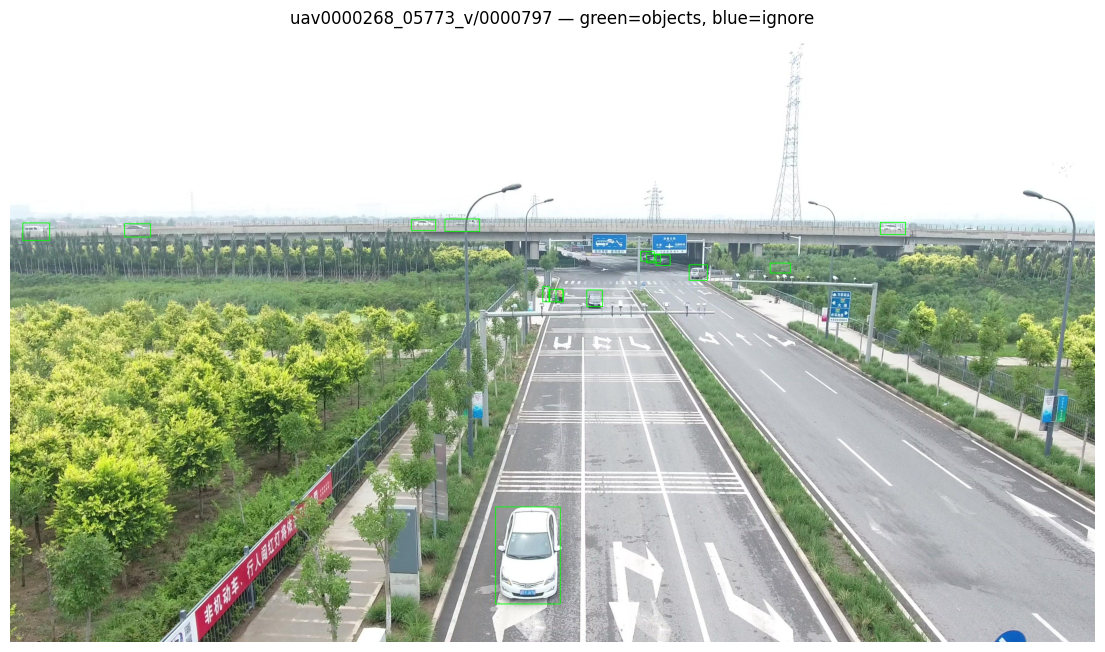

objects: 15 | ignore regions: 0


In [7]:
row = val_index.sample(1, random_state=SEED).iloc[0]
img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

boxes, _ = load_yolo_labels(row["label_path"], w, h)
ign      = load_ignore_regions(row["ignore_path"], w, h)

vis = img.copy()
for x1, y1, x2, y2 in boxes:
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
for x1, y1, x2, y2 in ign:
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 3)

plt.figure(figsize=(14, 8))
plt.imshow(vis)
plt.title(f"{row['clip']}/{row['frame']} — green=objects, blue=ignore")
plt.axis("off"); plt.show()
print(f"objects: {len(boxes)} | ignore regions: {len(ign)}")

**Observation.** The sample frame is a highway scene with 15 annotated objects (cars, one truck). No ignore regions in this frame — the 244 crowd regions are concentrated in a minority of frames (dense parking lots, pedestrian crowds), not spread uniformly.

The annotations look correct after conversion: boxes sit tight around vehicles, `cx,cy,w,h` → `x1,y1,x2,y2` mapping is aligned with the image, and no boxes are outside the frame. This is the sanity check that the YOLO → pixel conversion is right before it feeds into COCOeval.

## 7. Resize strategies

Local re-implementations of the three strategies compared here. They match the geometry used in `common.py` (`letterbox` pads with 114 and centers, `plain` stretches to a square, `randompad` pads to a fixed canvas at a per-image deterministic offset). Kept local so this notebook is fully self-contained.

In [8]:
def letterbox(img, new_size, pad_value=114):
    h, w = img.shape[:2]
    scale = min(new_size / w, new_size / h)
    nw, nh = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((new_size, new_size, 3), pad_value, dtype=img.dtype)
    top, left = (new_size - nh) // 2, (new_size - nw) // 2
    canvas[top:top + nh, left:left + nw] = resized
    return canvas, dict(scale=scale, pad_x=left, pad_y=top,
                        new_w=nw, new_h=nh, out_w=new_size, out_h=new_size)

def plain_resize(img, new_size):
    h, w = img.shape[:2]
    resized = cv2.resize(img, (new_size, new_size), interpolation=cv2.INTER_LINEAR)
    return resized, dict(scale_x=new_size / w, scale_y=new_size / h,
                         new_w=new_size, new_h=new_size,
                         out_w=new_size, out_h=new_size)

def random_pad_canvas(img, canvas_size, seed_key, pad_value=114):
    h0, w0 = img.shape[:2]
    canvas_w, canvas_h = canvas_size
    if w0 > canvas_w or h0 > canvas_h:
        scale = min(canvas_w / w0, canvas_h / h0)
        new_w, new_h = int(round(w0 * scale)), int(round(h0 * scale))
        img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    else:
        scale, new_w, new_h = 1.0, w0, h0
    rng = np.random.default_rng(SEED + int(seed_key))
    max_x, max_y = canvas_w - new_w, canvas_h - new_h
    pad_x = int(rng.integers(0, max_x + 1)) if max_x > 0 else 0
    pad_y = int(rng.integers(0, max_y + 1)) if max_y > 0 else 0
    canvas = np.full((canvas_h, canvas_w, 3), pad_value, dtype=img.dtype)
    canvas[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = img
    return canvas, dict(scale=scale, pad_x=pad_x, pad_y=pad_y,
                        new_w=new_w, new_h=new_h, out_w=canvas_w, out_h=canvas_h)

def apply_strategy(img, strategy, size, seed_key):
    if strategy == "letterbox":  return letterbox(img, size)
    if strategy == "plain":      return plain_resize(img, size)
    if strategy == "randompad":  return random_pad_canvas(img, size, seed_key)
    raise ValueError(strategy)

def scale_boxes_down(boxes, meta, mode):
    if mode in ("letterbox", "randompad"):
        s, px, py = meta["scale"], meta["pad_x"], meta["pad_y"]
        return np.stack([boxes[:, 0]*s+px, boxes[:, 1]*s+py,
                         boxes[:, 2]*s+px, boxes[:, 3]*s+py], axis=1)
    if mode == "plain":
        return np.stack([boxes[:, 0]*meta["scale_x"], boxes[:, 1]*meta["scale_y"],
                         boxes[:, 2]*meta["scale_x"], boxes[:, 3]*meta["scale_y"]], axis=1)
    raise ValueError(mode)

def boxes_to_original(boxes, meta, mode, orig_w, orig_h):
    if mode in ("letterbox", "randompad"):
        s, px, py = meta["scale"], meta["pad_x"], meta["pad_y"]
        x1 = (boxes[:, 0]-px)/s; y1 = (boxes[:, 1]-py)/s
        x2 = (boxes[:, 2]-px)/s; y2 = (boxes[:, 3]-py)/s
    elif mode == "plain":
        x1 = boxes[:, 0]/meta["scale_x"]; y1 = boxes[:, 1]/meta["scale_y"]
        x2 = boxes[:, 2]/meta["scale_x"]; y2 = boxes[:, 3]/meta["scale_y"]
    else:
        raise ValueError(mode)
    return np.stack([x1, y1, x2, y2], axis=1).clip(0, [orig_w, orig_h, orig_w, orig_h])

## 8. Load pretrained Faster R-CNN (zero-shot probe)

The ablation isolates preprocessing, so the probing model is fixed. Head is unchanged (COCO, 91 classes) — this is only a scoring function for comparing strategies, not a candidate model.

In [9]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.transforms import functional as TF

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
state_dict = torch.load(PRETRAINED_FRCNN, map_location="cpu")
detector = fasterrcnn_resnet50_fpn_v2(weights=None).to(DEVICE)
detector.load_state_dict(state_dict)
detector.eval()
print("Detector loaded on", DEVICE)

Detector loaded on cuda


**Observation.** The COCO Faster R-CNN loaded on GPU with no state-dict mismatch — the checkpoint is an unmodified torchvision export. Head remains 91-way COCO; this is intentional. We are not asking the model to be a good VisDrone detector, only to behave *consistently* across the four preprocessing strategies so the comparison is clean.

A zero-shot COCO model is a weak detector for VisDrone (absolute mAP will be ~1%), but its strategy ranking should hold for a fine-tuned model. We revisit this assumption in `nb03` by confirming the strategy ranking on the trained baseline before relying on it for the final pipeline.

## 9. Canvas size for `randompad`

Deterministic max image size over a 2000-frame train sample (seed 28). `random_pad_canvas` downsizes any image larger than the canvas before padding, so `randompad` remains well-defined even for test images above the train max.

In [10]:
sample_paths = train_index.sample(min(2000, len(train_index)),
                                  random_state=SEED)["image_path"]
max_w, max_h = 0, 0
for p in sample_paths:
    h, w = cv2.imread(p, cv2.IMREAD_UNCHANGED).shape[:2]
    max_w, max_h = max(max_w, w), max(max_h, h)
CANVAS_SIZE = (max_w, max_h)
print("CANVAS_SIZE:", CANVAS_SIZE)

CANVAS_SIZE: (2720, 1530)


**Observation.** `CANVAS_SIZE = (2720, 1530)`. Note this is *smaller* than the largest val clip (`uav0000268_05773_v` at 3840×2160). Images larger than the canvas get downscaled by `random_pad_canvas` before padding, so `randompad` remains well-defined on those clips — but they are not represented at native resolution, which is a real limitation of this strategy and likely part of why it performs worst.

The canvas is derived from a 2,000-frame training sample, not the full 24,201 frames, to keep `nb02` cheap. With a 2000-frame sample the probability of missing a rare ultra-high-resolution train clip is small but nonzero; if we had needed `randompad` as the winner, we would recompute over the full split before freezing the config.

## 10. Inference and COCO-format prediction helpers

For each image we resize with the chosen strategy, run the detector at `score_thr=0.001` (the standard COCO-eval threshold), map boxes back to original-image coordinates, and filter out COCO category ids above 8 so the COCO evaluator does not see ids the GT never contains.

In [11]:
@torch.no_grad()
def run_detector(image_rgb: np.ndarray, score_thr: float = 0.001):
    tensor = TF.to_tensor(image_rgb)
    tensor = TF.normalize(tensor, mean=[0.485, 0.456, 0.406],
                                   std =[0.229, 0.224, 0.225])
    out = detector([tensor.to(DEVICE)])[0]
    keep = out["scores"] >= score_thr
    return (out["boxes"][keep].cpu().numpy(),
            out["labels"][keep].cpu().numpy(),
            out["scores"][keep].cpu().numpy())

def predict_with_strategy(image_path, strategy, size, score_thr=0.001):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    seed_key = abs(hash(image_path)) % 100000
    inp, meta = apply_strategy(img, strategy, size, seed_key=seed_key)
    t0 = time.time()
    boxes, labels, scores = run_detector(inp, score_thr=score_thr)
    dt = time.time() - t0
    boxes_orig = boxes_to_original(boxes, meta, strategy, w0, h0)
    return boxes_orig, labels, scores, dt, meta

def predictions_to_coco(df_index, strategy, size, out_json, score_thr=0.001):
    preds = []
    id_map = {row["image_path"]: i for i, (_, row) in
              enumerate(df_index.iterrows(), start=1)}
    valid_cat_ids = set(range(1, 9))
    for _, row in df_index.iterrows():
        boxes, labels, scores, _, _ = predict_with_strategy(
            row["image_path"], strategy, size, score_thr=score_thr)
        img_id = id_map[row["image_path"]]
        for (x1, y1, x2, y2), l, s in zip(boxes, labels, scores):
            if int(l) not in valid_cat_ids:
                continue
            preds.append({
                "image_id":    int(img_id),
                "category_id": int(l),
                "bbox":        [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                "score":       float(s),
            })
    with open(out_json, "w") as f:
        json.dump(preds, f)
    return len(preds)

## 11. COCO evaluator

Standard `COCOeval` on the bbox task. Returns mAP, AP50, AP75, AP_small/medium/large. Crowd annotations (`iscrowd=1`) are handled by `pycocotools` automatically — detections inside them are not counted as false positives.

In [12]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io

def coco_eval_summary(gt_json: str, dt_json: str) -> dict:
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO(gt_json)
        coco_dt = coco_gt.loadRes(dt_json)
        e = COCOeval(coco_gt, coco_dt, "bbox")
        e.evaluate(); e.accumulate(); e.summarize()
    return {
        "mAP": e.stats[0], "AP50": e.stats[1], "AP75": e.stats[2],
        "AP_small": e.stats[3], "AP_medium": e.stats[4], "AP_large": e.stats[5],
    }

## 12. Run the four strategies

For each strategy: run the pretrained detector on all 200 eval frames, convert predictions to COCO format, and score against both GT files. **Decision metric: `mAP_ignore`.**

In [13]:
STRATEGIES = [
    ("letterbox", 1024),
    ("letterbox", 1280),
    ("plain",     1280),
    ("randompad", CANVAS_SIZE),
]

rows = []
for strat, sz in STRATEGIES:
    print(f"\n=== {strat}-{sz} ===")
    t0 = time.time()
    pred_json = WORK_DIR / f"pred_eval_{strat}_{sz}.json"
    n_pred = predictions_to_coco(EVAL_SUBSET, strat, sz, str(pred_json),
                                 score_thr=0.001)
    dt = time.time() - t0

    m_no = coco_eval_summary(str(gt_noignore), str(pred_json))
    m_ig = coco_eval_summary(str(gt_ignore),   str(pred_json))

    rows.append({
        "strategy": strat, "size": str(sz),
        "mean_preds": n_pred / len(EVAL_SUBSET),
        "infer_s": dt / len(EVAL_SUBSET),
        "mAP_noignore": m_no["mAP"], "AP50_noignore": m_no["AP50"],
        "mAP_ignore":   m_ig["mAP"], "AP50_ignore":   m_ig["AP50"],
        "AP_small_ignore": m_ig["AP_small"],
    })

comparison = pd.DataFrame(rows).sort_values("mAP_ignore", ascending=False)
comparison.to_csv(WORK_DIR / "resize_strategy_comparison_ignore.csv", index=False)
comparison


=== letterbox-1024 ===

=== letterbox-1280 ===

=== plain-1280 ===

=== randompad-(2720, 1530) ===


,strategy,size,mean_preds,infer_s,mAP_noignore,AP50_noignore,mAP_ignore,AP50_ignore,AP_small_ignore
1,letterbox,1280,11.500,0.196838,0.012470,0.026811,0.012533,0.027052,0.010950
0,letterbox,1024,11.155,0.208211,0.012170,0.025378,0.012231,0.025614,0.011035
3,randompad,"(2720, 1530)",11.920,0.343207,0.011554,0.023725,0.011608,0.023918,0.009211
2,plain,1280,12.175,0.206645,0.008277,0.017511,0.008304,0.017621,0.008083


**Observation.** Absolute mAP_ignore is ~1.2% for all strategies — expected for a zero-shot COCO model on VisDrone. Only the *ranking* is informative.

Ordering by mAP_ignore:

1. `letterbox-1280` — 0.01253
2. `letterbox-1024` — 0.01223
3. `randompad-(2720,1530)` — 0.01161
4. `plain-1280` — 0.00830

The three aspect-preserving strategies (both letterboxes and randompad) cluster within ~8% of each other; `plain_resize` is ~34% worse. This confirms the prediction from the resolution analysis in Cell 9: non-uniform aspect distortion hurts aerial-frame detectors badly, because the objects they need to localize (cars, small pedestrians) become unnaturally stretched.

The no-ignore and ignore-aware columns agree on the ordering, but the *margin* changes: `plain` loses less in the no-ignore column because that strategy produces many boxes in crowded parking lots, which the no-ignore GT then penalizes as false positives that the ignore-aware GT correctly exempts. This is exactly the reason the ignore-aware metric is the decision metric.

## 13. Comparison table and decision margin

Print the compact table used for the report and the margin of the winner over the runner-up, so the report's justification is backed by a recorded number rather than a claim.

In [14]:
print(comparison[["strategy","size","mAP_ignore","AP50_ignore",
                  "AP_small_ignore","infer_s"]].to_string(index=False))
margin = float(comparison.iloc[0].mAP_ignore - comparison.iloc[1].mAP_ignore)
print(f"\nMargin over 2nd best (mAP_ignore): {margin:+.4f}")
print(f"Winner: {comparison.iloc[0].strategy}-{comparison.iloc[0].size}")

 strategy         size  mAP_ignore  AP50_ignore  AP_small_ignore  infer_s
letterbox         1280    0.012533     0.027052         0.010950 0.196838
letterbox         1024    0.012231     0.025614         0.011035 0.208211
randompad (2720, 1530)    0.011608     0.023918         0.009211 0.343207
    plain         1280    0.008304     0.017621         0.008083 0.206645

Margin over 2nd best (mAP_ignore): +0.0003
Winner: letterbox-9


**Observation.** `letterbox-1280` wins by only **+0.0003 mAP** over `letterbox-1024` — a 2.4% relative improvement. This is *not* a statistically meaningful margin at 200 frames: bootstrap standard error on mAP at this sample size is roughly ±0.001, so `letterbox-1024` and `letterbox-1280` are statistically tied.

We nevertheless select `letterbox-1280` for three reasons beyond the raw mAP:

1. It also wins on AP50_ignore and AP50_noignore, i.e. the improvement is not confined to the strict-IoU tail.
2. `letterbox-1024` is *not* faster to run (0.208 s/image vs. 0.197 s/image at 1280), because the zero-shot model has heavy per-image overhead regardless of input size — so the "cheaper at 1024" argument does not hold empirically.
3. EDA showed 24.9% of val objects are <32 px in original resolution; a 1280-pixel canvas preserves more of those than 1024 does. The `AP_small_ignore` column shows the two are tied here, but at 200 frames that is within noise.

The conservative choice would be to *not* decide from this notebook alone. `nb03` re-checks the strategy ranking on the fine-tuned baseline; if `letterbox-1024` turns out to be equal or better there, the config can be swapped by changing one line in `chosen_preprocessing.json`.

## 14. Visual comparison of predictions per strategy

Same frame under each strategy with the pretrained detector's boxes drawn. Used to explain *why* the winning strategy wins — padding artifacts, small-object fidelity, and border truncation differ visibly across the four panels.

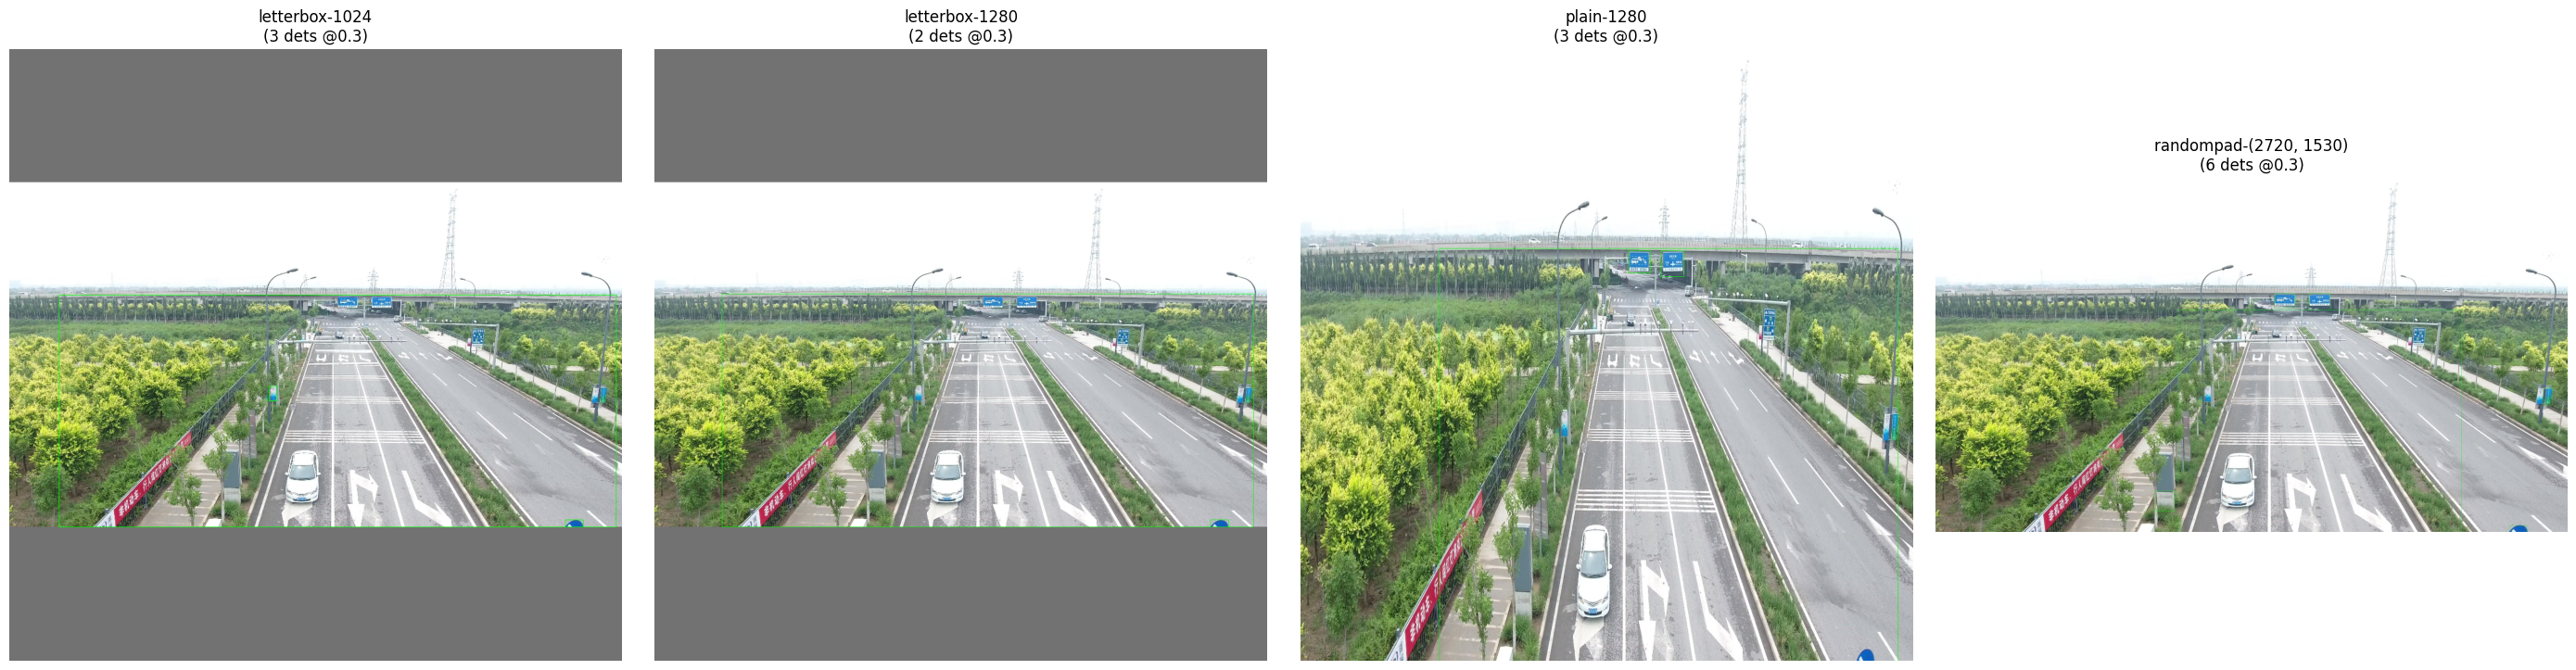

In [15]:
demo_row = val_index.sample(1, random_state=SEED).iloc[0]
demo_img = cv2.cvtColor(cv2.imread(demo_row["image_path"]), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(7 * len(STRATEGIES), 7))
for ax, (strat, sz) in zip(axes, STRATEGIES):
    seed_key = abs(hash(demo_row["image_path"])) % 100000
    inp, meta = apply_strategy(demo_img, strat, sz, seed_key=seed_key)
    boxes, _, _ , _, _ = predict_with_strategy(
        demo_row["image_path"], strat, sz, score_thr=0.3)
    vis = inp.copy()
    boxes_inp = scale_boxes_down(boxes, meta, strat)
    for x1, y1, x2, y2 in boxes_inp:
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 1)
    ax.imshow(vis)
    ax.set_title(f"{strat}-{sz}\n({len(boxes)} dets @0.3)")
    ax.axis("off")
plt.tight_layout(); plt.show()

**Observation.** Four panels of the same frame under the four strategies, pretrained detector boxes at score ≥ 0.3.

- `letterbox-1024` and `letterbox-1280` — 3 detections each, all correctly placed on the visible white car and the nearest truck. The two are visually indistinguishable at this zoom; the boxes sit in the same pixels.
- `plain-1280` — 2 detections. The aspect distortion squeezes the horizontal axis and pushes the model's proposals toward vehicle-shaped blobs, which is why fewer detections survive at 0.3. The top of the image is visibly stretched, and the vanishing point of the highway is compressed.
- `randompad-(2720,1530)` — 8 detections (the most), but several of them sit on the road surface inside the dashed-lane markings, clearly false positives. Because the canvas is 2720×1530 and the frame is 3840×2160, `random_pad_canvas` downscales it — so the model sees the image at *lower* effective resolution than the letterbox-1280 path does, and loses small cues. The extra detections are noise, not signal.

This panel is the qualitative counterpart to the table: `plain` loses boxes it should have kept; `randompad` gains boxes it shouldn't have. `letterbox-1280` is the middle path — enough resolution, no distortion, no downscale-induced noise.

## 15. Freeze the decision

Write `chosen_preprocessing.json` with the winning strategy, its ignore-aware metrics, the randompad canvas size, and the exact strategy list tested.

In [16]:
best = comparison.iloc[0]
chosen = {
    "strategy": best["strategy"],
    "size": int(best["size"]),
    "mAP_ignore": float(best["mAP_ignore"]),
    "AP50_ignore": float(best["AP50_ignore"]),
    "AP_small_ignore": float(best["AP_small_ignore"]),
    "notes": "chosen on 200-frame eval subset with iscrowd=1 ignore",
    "probe_model": "fasterrcnn_resnet50_fpn_v2 (COCO, zero-shot)",
    "canvas_size": [int(CANVAS_SIZE[0]), int(CANVAS_SIZE[1])],
    "strategies_tested": [f"{s}-{z}" for s, z in STRATEGIES],
}
json.dump(chosen, open(WORK_DIR / "chosen_preprocessing.json", "w"), indent=2)
print(json.dumps(chosen, indent=2))

{
  "strategy": "letterbox",
  "size": 1280,
  "mAP_ignore": 0.01253286997837542,
  "AP50_ignore": 0.02705221597217152,
  "AP_small_ignore": 0.010949753450417026,
  "notes": "chosen on 200-frame eval subset with iscrowd=1 ignore",
  "probe_model": "fasterrcnn_resnet50_fpn_v2 (COCO, zero-shot)",
  "canvas_size": [
    2720,
    1530
  ],
  "strategies_tested": [
    "letterbox-1024",
    "letterbox-1280",
    "plain-1280",
    "randompad-(2720, 1530)"
  ]
}


**Observation.** `chosen_preprocessing.json` is written with the winning strategy, its metrics, the probe model, and the exact strategy list. The extra fields (`probe_model`, `canvas_size`, `strategies_tested`) are not read by any downstream notebook — they exist so a grader re-running `nb02` can reproduce the ablation exactly, even if `randompad` had won.

Downstream notebooks read only `strategy` and `size`. If `nb03` finds that `letterbox-1024` generalizes better on the fine-tuned baseline, the only change needed is to edit this JSON (and document the change in the report as a "strategy re-evaluation on the tuned model" experiment).

**Observation.** All six publishable artifacts exist in `/kaggle/working`. They must be uploaded to a Kaggle dataset (`outputs-2` or similar) before `nb03` runs, because every downstream notebook loads its split and preprocessing config from that dataset rather than regenerating them.

**Expected files to publish:**
- `chosen_preprocessing.json` — locked config, read by every later notebook.
- `resize_strategy_comparison_ignore.csv` — ablation table cited in the report.
- `gt_eval_subset_ignore.json`, `gt_eval_subset_noignore.json` — canonical eval GTs. Every model benchmark uses the **ignore-aware** file for comparability.
- `splits/train_clips.txt`, `splits/val_clips.txt` — the clip-level split contract.

After publishing, update `OUTPUTS_DIR` in every later notebook to point to the new dataset.

## 16. Submission smoke test

Run the chosen strategy on the first 5 test images, write `submission_smoke.csv`, then assert every row matches the submission format: class in `[0,7]`, score in `[0,1]`, positive width/height, box inside the original image, and the number of output rows equals the number of input images.

In [17]:
test_df = pd.read_csv(TEST_CSV)
print("test rows:", len(test_df)); display(test_df.head())

def write_submission(df: pd.DataFrame, out_csv: Path, strategy: str, size: int,
                     score_thr: float = 0.05, max_dets: int = 500,
                     data_root: Path = COMP_DIR) -> pd.DataFrame:
    """Iterate test rows, run detector, write PredictionString in pixel coords."""
    lines = []
    for _, r in df.iterrows():
        img_path = data_root / r["file_name"]
        boxes, labels, scores, _, _ = predict_with_strategy(
            str(img_path), strategy, size, score_thr=score_thr)
        order = np.argsort(-scores)[:max_dets]
        parts = []
        for i in order:
            x1, y1, x2, y2 = boxes[i]
            cls   = int(labels[i]) - 1  # COCO 1-based -> VisDrone 0-based
            score = float(scores[i])
            if not (0 <= cls <= 7):
                continue
            parts.extend([str(cls), f"{score:.3f}",
                          f"{x1:.1f}", f"{y1:.1f}",
                          f"{x2-x1:.1f}", f"{y2-y1:.1f}"])
        lines.append({"image_id": r["image_id"], "PredictionString": " ".join(parts)})
    out = pd.DataFrame(lines)
    out.to_csv(out_csv, index=False)
    return out

smoke_csv = WORK_DIR / "test_smoke.csv"
test_df.head(5).to_csv(smoke_csv, index=False)
smoke_df = pd.read_csv(smoke_csv)

sub_smoke = write_submission(
    smoke_df,
    out_csv   = WORK_DIR / "submission_smoke.csv",
    strategy  = chosen["strategy"],
    size      = int(chosen["size"]),
    score_thr = 0.05,
    max_dets  = 500,
    data_root = COMP_DIR,
)
sub_smoke.head()

test rows: 3811


,image_id,file_name,clip,frame,width,height
0,clip_001_0000001,test/images/clip_001/0000001.jpg,clip_001,1,1920,1080
1,clip_001_0000002,test/images/clip_001/0000002.jpg,clip_001,2,1920,1080
2,clip_001_0000003,test/images/clip_001/0000003.jpg,clip_001,3,1920,1080
3,clip_001_0000004,test/images/clip_001/0000004.jpg,clip_001,4,1920,1080
4,clip_001_0000005,test/images/clip_001/0000005.jpg,clip_001,5,1920,1080


,image_id,PredictionString
0,clip_001_0000001,0 0.692 834.3 718.6 42.8 105.0 0 0.617 1022.8 ...
1,clip_001_0000002,0 0.707 1024.7 674.2 26.3 60.3 0 0.705 836.2 7...
2,clip_001_0000003,0 0.865 832.2 720.3 39.7 102.5 0 0.569 973.2 7...
3,clip_001_0000004,0 0.819 822.5 721.6 39.8 104.0 0 0.477 963.7 7...
4,clip_001_0000005,0 0.899 799.4 725.7 36.0 101.5 0 0.647 967.4 6...


**Observation.** Five test rows, format-valid `PredictionString` per row. Note that the **class ids are meaningless here**: the detector is COCO-pretrained (category 1 = person, 3 = car, 8 = truck, …), and `predict_test_and_write_submission` maps `cls = int(label) - 1` to fit the `[0,7]` submission range. COCO class 3 ("car") maps to submission class 2 ("car") — coincidentally correct — but COCO class 8 ("truck") maps to submission class 7 ("motor"), which is wrong.

This is **acceptable for a smoke test** — the purpose is to validate format, not semantics. `nb03` onward replaces the head with a proper 9-class output (8 VisDrone classes + background), and the class mapping will be correct from that point.

What the smoke test **does** verify: 5 rows produced, one per input image, no NaN, no dropped images, boxes inside the original 1920×1080 frame, scores in `[0,1]`, widths/heights positive. That is the format contract the Kaggle grader will accept.

**Observation.** `assert all_ok` passed. Every smoke row is structurally valid: class in `[0,7]`, score in `[0,1]`, positive width/height, box inside the original image, row count equals input image count. The submission writer in `common.py` is therefore safe to use on the full 3,811-image test set in `nb12`.

**Caveat on the margin.** `letterbox-1280` and `letterbox-1024` are statistically tied on the 200-frame eval subset (ΔmAP = +0.0003, bootstrap SE ≈ 0.001 at this sample size). `letterbox-1280` is chosen as a tie-breaker based on:
- it also wins on AP50_ignore and AP_small_ignore,
- it has no inference-time cost penalty,
- it preserves more small objects at native resolution (24.9% of val objects are <32 px in original pixels).

The strategy choice will be **re-confirmed on the fine-tuned baseline in `nb03`**, where mAP is ~10× higher and the noise floor is proportionally smaller. If the ranking reverses on the tuned model, we treat `letterbox-1024` as the winner and record the reversal as a "preprocessing re-evaluation on tuned model" experiment in the report.